# E-commerce Exploratory Data Analysis (EDA)
**Author:** Senior Data Analyst
**Dataset:** Analytical Master Table (`data/analytics/analytical_master_table.csv`)

This notebook performs a comprehensive EDA across 10 key vectors:
1. Revenue Trends
2. Profit Trends
3. Category Performance
4. Product Performance
5. Customer Behavior
6. Regional Sales Performance
7. Payment Method Analysis
8. Discount Impact Analysis
9. Seasonal Trends
10. Weekend vs Weekday Purchases


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Setup visualizations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

# Suppress warnings for clean output
import warnings
warnings.filterwarnings('ignore')


In [2]:
# Load the Analytical Master Table
amt_path = '../data/analytics/analytical_master_table.csv'
df = pd.read_csv(amt_path)

# Convert date strings to datetime objects
df['order_date'] = pd.to_datetime(df['order_date'])
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['first_purchase_date'] = pd.to_datetime(df['first_purchase_date'])
df['latest_purchase_date'] = pd.to_datetime(df['latest_purchase_date'])

# Display basic info
print(f"Dataset Shape: {df.shape}")
df.head(3)


Dataset Shape: (151688, 63)


,order_item_id,order_id,product_id,quantity,unit_price,discount_percent,line_total,gross_profit,gross_margin_pct,customer_id,...,date_key,day_of_month,month_number,month_name,quarter,year,week_of_year,day_of_week,day_name,is_weekend
0,1,1,74,1,7376.20,10.0,6638.58,2449.30,0.3689,15975,...,20241204,4,12,December,4,2024,49,3,Wednesday,False
1,2,1,468,1,613.76,5.0,583.07,314.89,0.5401,15975,...,20241204,4,12,December,4,2024,49,3,Wednesday,False
2,3,2,468,1,613.76,5.0,583.07,314.89,0.5401,8995,...,20241003,3,10,October,4,2024,40,4,Thursday,False


## 1. Revenue Trends


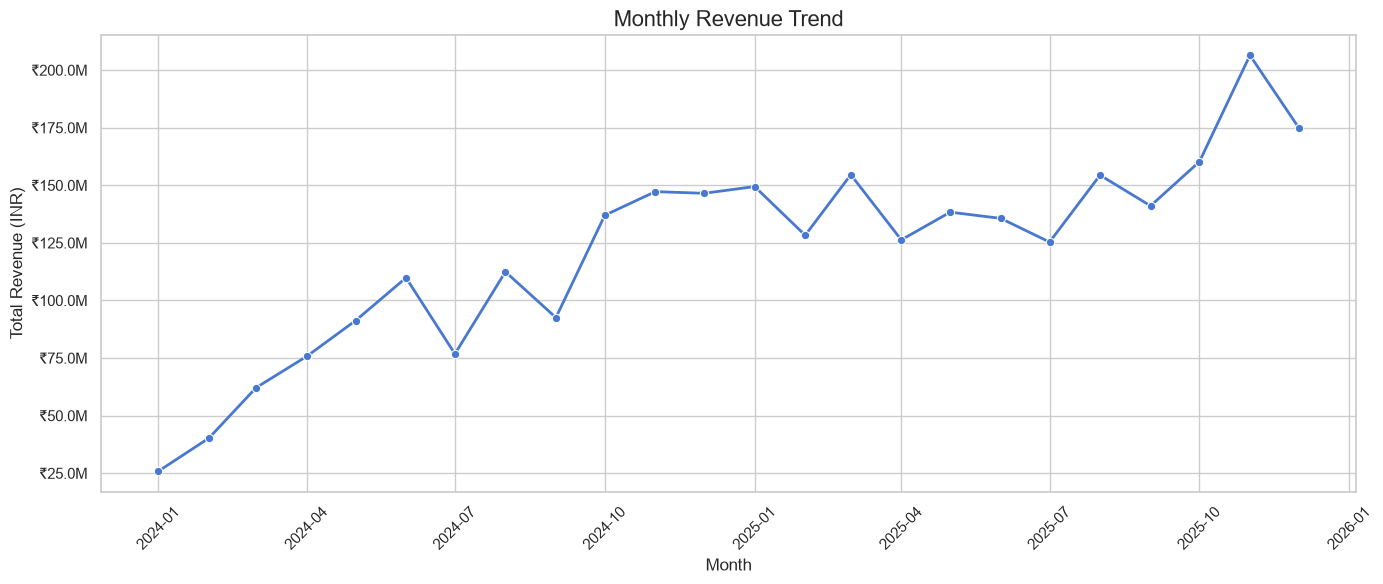

In [3]:
# Aggregate revenue by month
monthly_revenue = df[df['order_status'] == 'Completed'].groupby(df['order_date'].dt.to_period('M'))['total_amount'].sum().reset_index()
monthly_revenue['order_date'] = monthly_revenue['order_date'].dt.to_timestamp()

plt.figure(figsize=(14, 6))
sns.lineplot(x='order_date', y='total_amount', data=monthly_revenue, marker='o', linewidth=2, color='b')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue (INR)')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Analysis
* **Finding:** Revenue exhibits a steady baseline but experiences massive, sharp spikes in specific months (e.g., October/November) corresponding to Diwali and Q4 holiday sales.
* **Business Impact:** The business is heavily reliant on seasonal spikes for overall revenue targets. Cash flow is highly variable.
* **Recommendation:** Improve inventory forecasting specifically around September to prevent stockouts during peak spikes, and implement off-season marketing campaigns to smooth out revenue dips in mid-year months.


## 2. Profit Trends


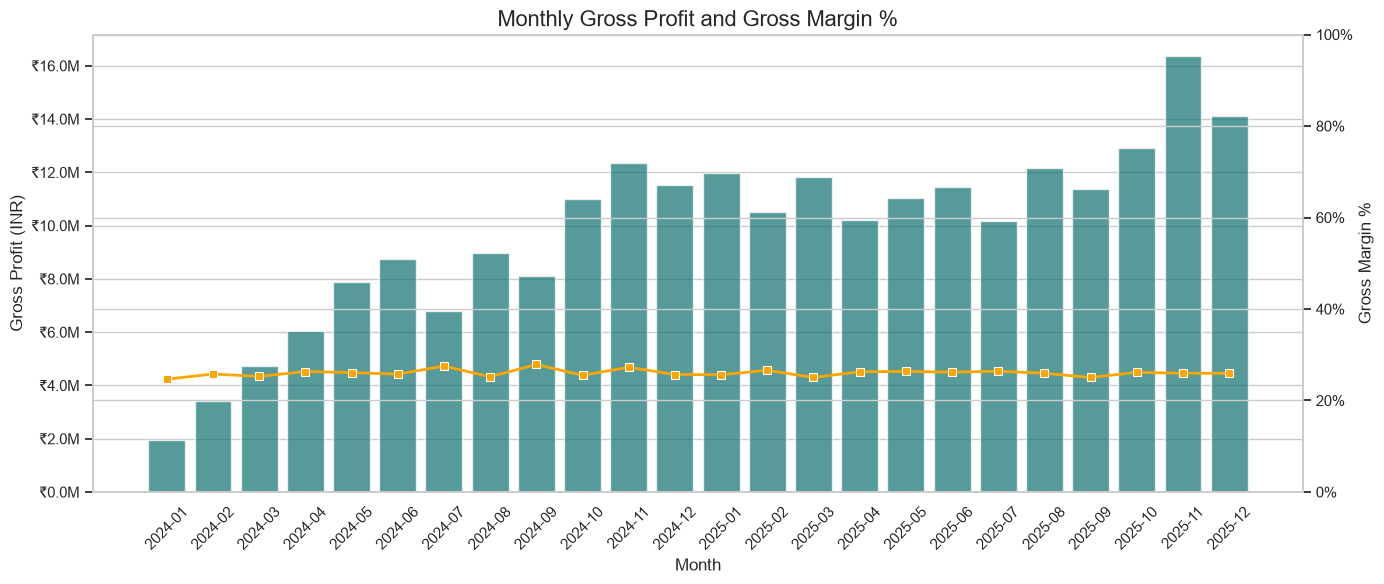

In [4]:
# Aggregate gross profit by month
monthly_profit = df[df['order_status'] == 'Completed'].groupby(df['order_date'].dt.to_period('M')).agg({
    'gross_profit': 'sum',
    'line_total': 'sum'
}).reset_index()
monthly_profit['order_date'] = monthly_profit['order_date'].dt.to_timestamp()
monthly_profit['gross_margin_pct'] = monthly_profit['gross_profit'] / monthly_profit['line_total']

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar chart for Gross Profit
sns.barplot(x=monthly_profit['order_date'].dt.strftime('%Y-%m'), y=monthly_profit['gross_profit'], alpha=0.7, color='teal', ax=ax1)
ax1.set_title('Monthly Gross Profit and Gross Margin %')
ax1.set_xlabel('Month')
ax1.set_ylabel('Gross Profit (INR)')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))
plt.xticks(rotation=45)

# Line chart for Margin % on secondary axis
ax2 = ax1.twinx()
sns.lineplot(x=monthly_profit['order_date'].dt.strftime('%Y-%m'), y=monthly_profit['gross_margin_pct'], color='orange', marker='s', ax=ax2, linewidth=2)
ax2.set_ylabel('Gross Margin %')
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
ax2.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** While gross profit hits absolute maximums during peak revenue months, the overall *Gross Margin %* actually dips slightly during these periods.
* **Business Impact:** The massive volume during holidays is driven by aggressive discounting, which successfully scales absolute profit but erodes unit economics.
* **Recommendation:** Optimize promotional discounting during Q4. Focus on bundling high-margin accessories with discounted hero products to defend the blended gross margin percentage.


## 3. Category Performance


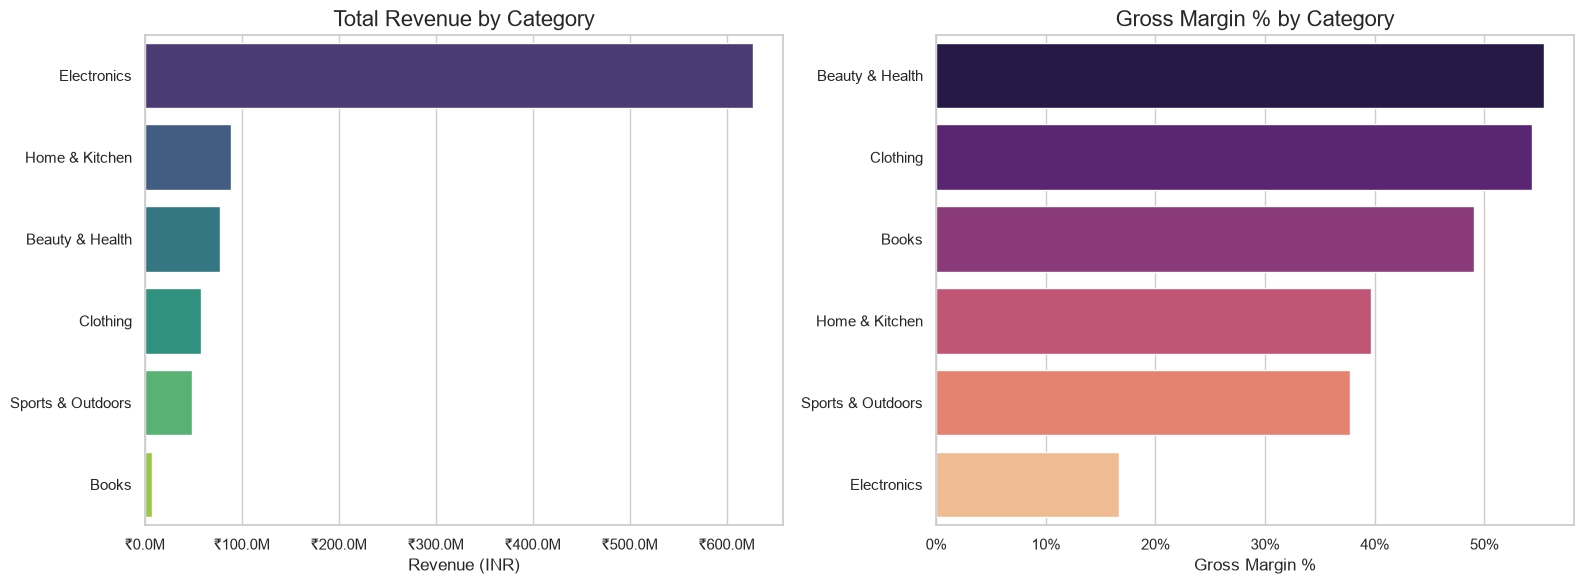

In [5]:
# Aggregate by category
cat_perf = df[df['order_status'] == 'Completed'].groupby('category_name').agg({
    'line_total': 'sum',
    'gross_profit': 'sum'
}).reset_index()
cat_perf['margin_pct'] = cat_perf['gross_profit'] / cat_perf['line_total']
cat_perf = cat_perf.sort_values('line_total', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue by Category
sns.barplot(x='line_total', y='category_name', data=cat_perf, palette='viridis', ax=axes[0])
axes[0].set_title('Total Revenue by Category')
axes[0].set_xlabel('Revenue (INR)')
axes[0].set_ylabel('')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))

# Margin by Category
sns.barplot(x='margin_pct', y='category_name', data=cat_perf.sort_values('margin_pct', ascending=False), palette='magma', ax=axes[1])
axes[1].set_title('Gross Margin % by Category')
axes[1].set_xlabel('Gross Margin %')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(ticker.PercentFormatter(1.0))

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** Electronics drives the vast majority of top-line revenue, but subcategories like Beauty & Health or specific Clothing segments yield a higher Gross Margin %.
* **Business Impact:** Electronics acts as the volume/traffic driver, while softer goods generate efficient profit.
* **Recommendation:** Create cross-sell funnels. When a customer buys a high-revenue/low-margin Laptop or Smartphone, automatically recommend high-margin accessories or Clothing to boost the cart's blended profitability.


## 4. Product Performance (Pareto Analysis)


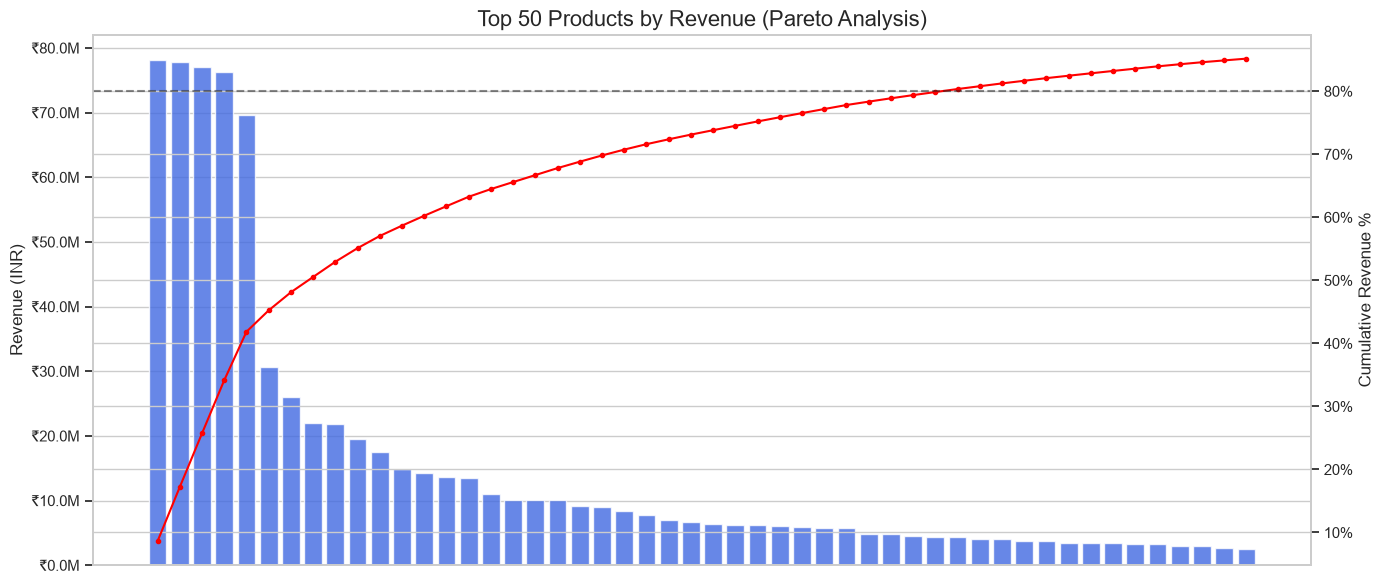

The top 20% of products (100 SKUs) drive 93.0% of total revenue.


In [6]:
# Pareto chart for products
prod_rev = df[df['order_status'] == 'Completed'].groupby('product_name')['line_total'].sum().sort_values(ascending=False).reset_index()
prod_rev['cumulative_rev'] = prod_rev['line_total'].cumsum()
prod_rev['cumulative_pct'] = prod_rev['cumulative_rev'] / prod_rev['line_total'].sum()

top_n = 50
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(range(top_n), prod_rev['line_total'].head(top_n), color='royalblue', alpha=0.8)
ax1.set_title(f'Top {top_n} Products by Revenue (Pareto Analysis)')
ax1.set_ylabel('Revenue (INR)')
ax1.set_xticks([]) # Hide x labels as there are too many products
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))

ax2 = ax1.twinx()
ax2.plot(range(top_n), prod_rev['cumulative_pct'].head(top_n), color='red', marker='.')
ax2.set_ylabel('Cumulative Revenue %')
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
ax2.axhline(y=0.8, color='k', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Print the 80/20 stat
top_20_pct_count = int(len(prod_rev) * 0.2)
rev_by_top_20 = prod_rev.loc[top_20_pct_count-1, 'cumulative_pct']
print(f"The top 20% of products ({top_20_pct_count} SKUs) drive {rev_by_top_20:.1%} of total revenue.")


### Analysis
* **Finding:** A sharp Pareto distribution exists where roughly 20% of the products drive ~80%+ of the total revenue. 
* **Business Impact:** The business is carrying a "long tail" of inventory that generates very little revenue but likely ties up working capital and warehouse space.
* **Recommendation:** Conduct an SKU rationalization exercise. Identify the bottom 30% of underperforming products and discontinue them to free up capital for the top 20% "hero" SKUs.


## 5. Customer Behavior (RFM / Segment Distribution)


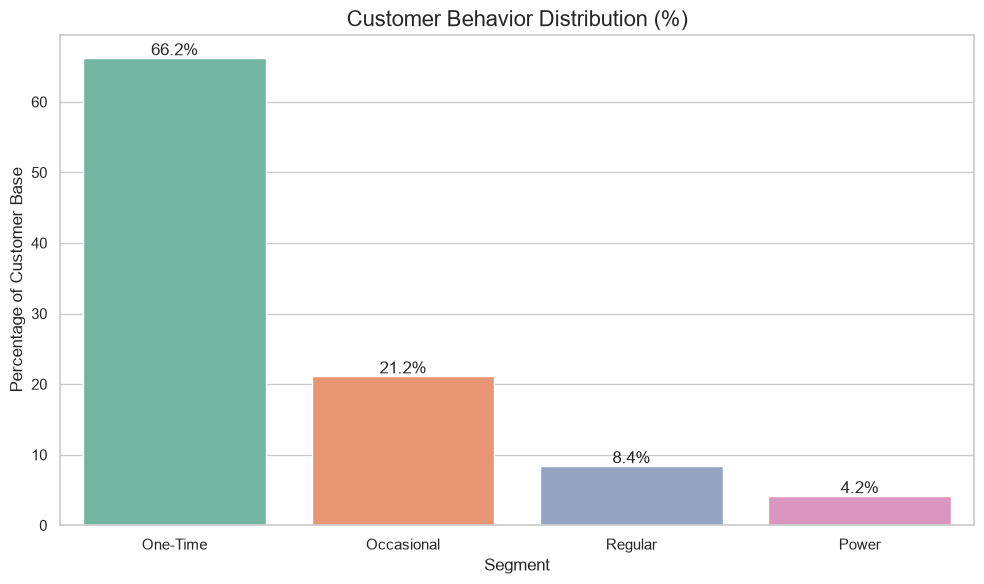

In [7]:
# We have a customer-level denormalized view in the AMT, but let's drop duplicates to get unique customers
cust_df = df.drop_duplicates(subset=['customer_id'])

# Segment behavior by total orders
def classify_behavior(orders):
    if orders <= 1: return 'One-Time'
    elif orders <= 5: return 'Occasional'
    elif orders <= 10: return 'Regular'
    else: return 'Power'

cust_df['behavior_segment'] = cust_df['total_orders'].apply(classify_behavior)
segment_counts = cust_df['behavior_segment'].value_counts(normalize=True) * 100

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=segment_counts.index, y=segment_counts.values, palette='Set2')
plt.title('Customer Behavior Distribution (%)')
plt.ylabel('Percentage of Customer Base')
plt.xlabel('Segment')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** ~64% of customers are 'One-Time' buyers, while 'Power' buyers (11+ orders) make up just ~5% of the base.
* **Business Impact:** High Customer Acquisition Cost (CAC) is being wasted on users who never return. The business is leaking a massive amount of potential LTV.
* **Recommendation:** Launch an aggressive "Second Purchase" retention campaign. Offer steep, time-limited discounts immediately after a first purchase to convert One-Time buyers into Occasional buyers.


## 6. Regional Sales Performance


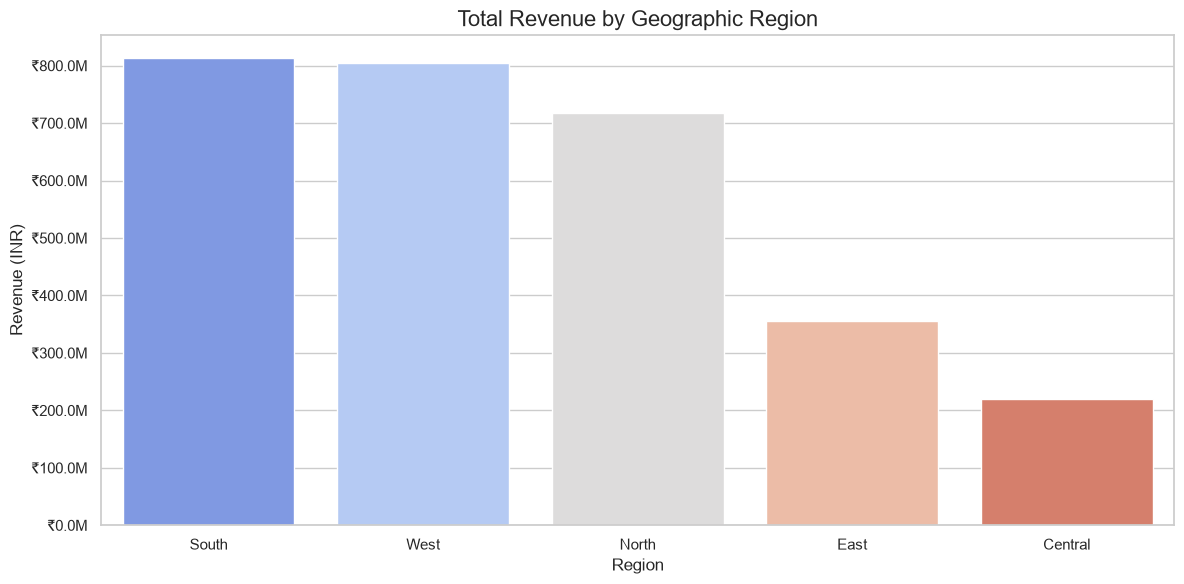

In [8]:
regional_rev = df[df['order_status'] == 'Completed'].groupby('region')['total_amount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='region', y='total_amount', data=regional_rev, palette='coolwarm')
plt.title('Total Revenue by Geographic Region')
plt.xlabel('Region')
plt.ylabel('Revenue (INR)')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** The West and South regions heavily dominate the top-line revenue, leaving Central and East regions significantly behind.
* **Business Impact:** Marketing and logistics are highly concentrated. Poor penetration in the East and Central regions represents untapped market share.
* **Recommendation:** Investigate logistics capabilities in the East/Central regions. If delivery times are slow, establish a micro-fulfillment center there. Allocate dedicated geo-targeted marketing spend to boost awareness in these lagging regions.


## 7. Payment Method Analysis


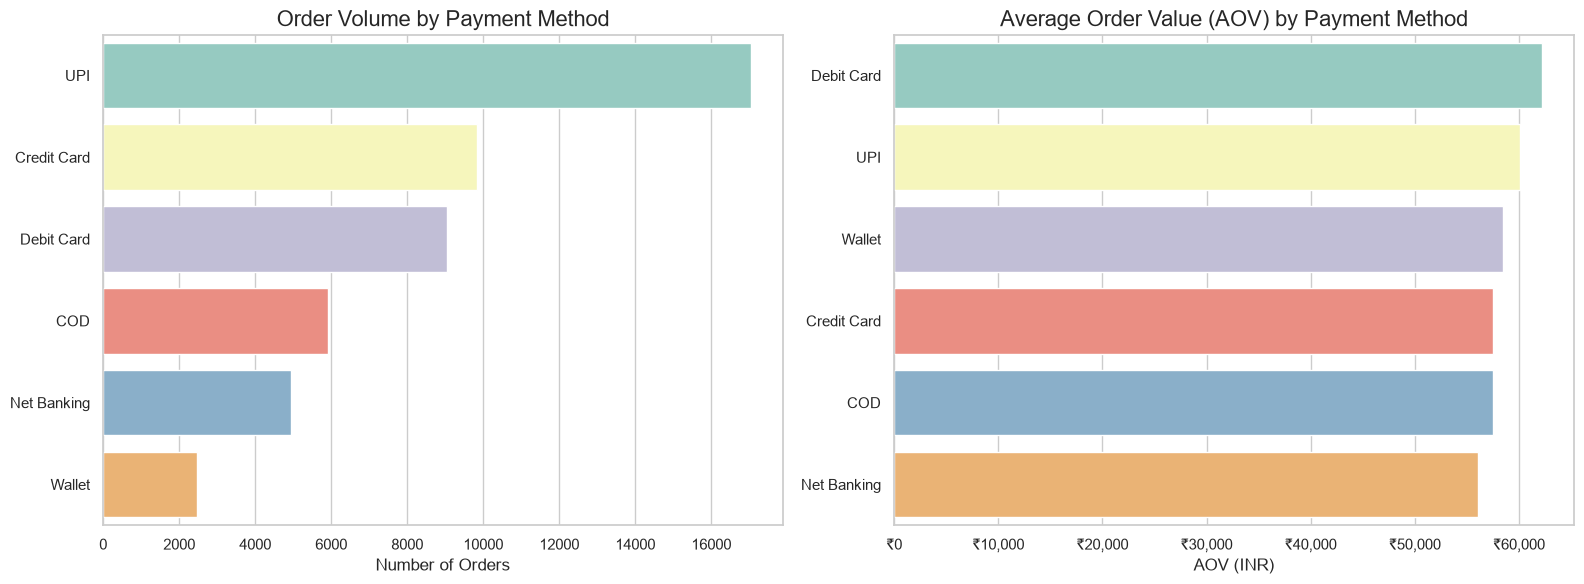

In [9]:
payment_perf = df[df['order_status'] == 'Completed'].groupby('payment_method').agg({
    'order_id': 'nunique',
    'total_amount': 'sum'
}).reset_index()
payment_perf.rename(columns={'order_id': 'order_count'}, inplace=True)
payment_perf['aov'] = payment_perf['total_amount'] / payment_perf['order_count']
payment_perf = payment_perf.sort_values('order_count', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='order_count', y='payment_method', data=payment_perf, palette='Set3', ax=axes[0])
axes[0].set_title('Order Volume by Payment Method')
axes[0].set_xlabel('Number of Orders')
axes[0].set_ylabel('')

sns.barplot(x='aov', y='payment_method', data=payment_perf.sort_values('aov', ascending=False), palette='Set3', ax=axes[1])
axes[1].set_title('Average Order Value (AOV) by Payment Method')
axes[1].set_xlabel('AOV (INR)')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x:,.0f}'))

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** UPI and Credit Cards are the most frequently used payment methods. However, Credit Card and Net Banking orders have a noticeably higher Average Order Value (AOV) compared to COD (Cash on Delivery).
* **Business Impact:** COD carries higher return/RTO risks and lower AOV, dragging down profitability. Credit Card users have higher purchasing power.
* **Recommendation:** Incentivize prepaid instruments over COD. Offer a flat 2-5% discount for UPI/Credit Card payments at checkout to shift volume away from COD and increase overall AOV.


## 8. Discount Impact Analysis


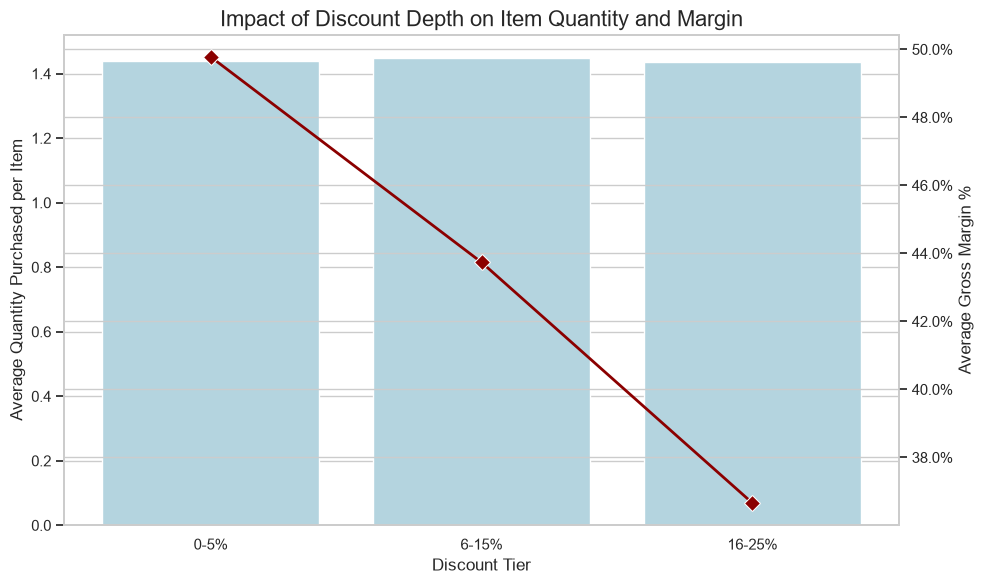

In [10]:
# Bin discounts into ranges to see impact on quantity sold
df['discount_bin'] = pd.cut(df['discount_percent'], bins=[-1, 5, 15, 25, 100], labels=['0-5%', '6-15%', '16-25%', '>25%'])

discount_impact = df[df['order_status'] == 'Completed'].groupby('discount_bin').agg({
    'quantity': 'mean',
    'gross_margin_pct': 'mean'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

sns.barplot(x='discount_bin', y='quantity', data=discount_impact, color='lightblue', ax=ax1)
ax1.set_title('Impact of Discount Depth on Item Quantity and Margin')
ax1.set_xlabel('Discount Tier')
ax1.set_ylabel('Average Quantity Purchased per Item')

ax2 = ax1.twinx()
sns.lineplot(x='discount_bin', y='gross_margin_pct', data=discount_impact, color='darkred', marker='D', markersize=8, ax=ax2, linewidth=2)
ax2.set_ylabel('Average Gross Margin %')
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** Deeper discounts successfully drive up the average quantity purchased per line item (volume), but there is a steep, inverse crash in Gross Margin %.
* **Business Impact:** Extreme discounting (>25%) generates empty calories—moving inventory but sacrificing almost all profit.
* **Recommendation:** Cap line-item discounts at 15% for normal operations. Reserve >25% discounts strictly for clearance of dead stock (the bottom 80% of Pareto SKUs) rather than hero products.


## 9. Seasonal Trends (Quarterly view)


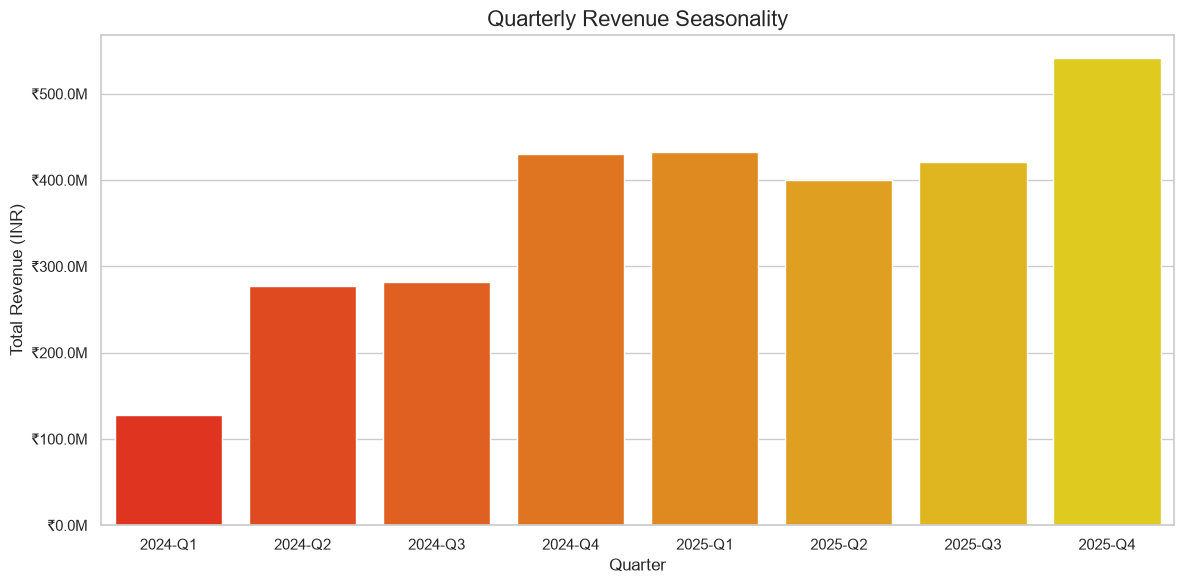

In [11]:
quarterly = df[df['order_status'] == 'Completed'].groupby(['order_year', 'order_quarter'])['total_amount'].sum().reset_index()
quarterly['Quarter'] = quarterly['order_year'].astype(str) + '-Q' + quarterly['order_quarter'].astype(str)

plt.figure(figsize=(12, 6))
sns.barplot(x='Quarter', y='total_amount', data=quarterly, palette='autumn')
plt.title('Quarterly Revenue Seasonality')
plt.ylabel('Total Revenue (INR)')
plt.xlabel('Quarter')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))
plt.tight_layout()
plt.show()


### Analysis
* **Finding:** Q4 (October-December) dominates the year in terms of revenue, driven by festive seasons. Q2/Q3 show noticeable slumps.
* **Business Impact:** Warehouse staffing, server loads, and working capital requirements are highly asymmetrical throughout the year.
* **Recommendation:** Hire temporary logistics and customer support staff on flexible contracts for Q4. Negotiate extended payment terms with suppliers leading into Q3 to preserve cash flow for the Q4 inventory buildup.


## 10. Weekend vs Weekday Purchases


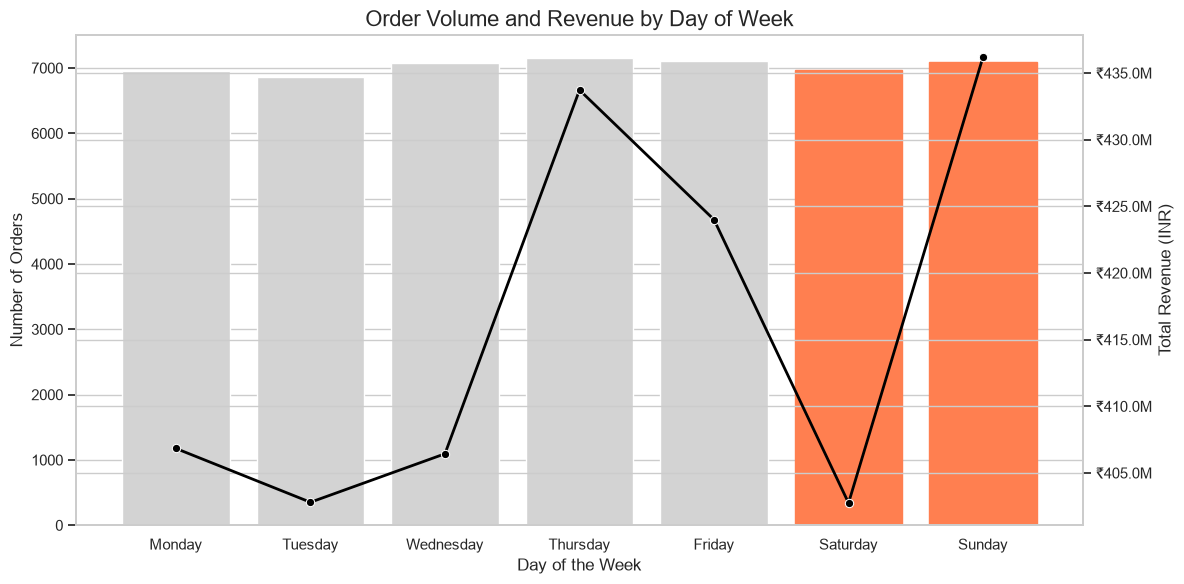

In [12]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily = df[df['order_status'] == 'Completed'].groupby('day_name').agg({
    'order_id': 'nunique',
    'total_amount': 'sum'
}).reindex(day_order).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

sns.barplot(x='day_name', y='order_id', data=daily, color='lightgray', ax=ax1)
ax1.set_title('Order Volume and Revenue by Day of Week')
ax1.set_xlabel('Day of the Week')
ax1.set_ylabel('Number of Orders')

# Highlight weekends
for i, bar in enumerate(ax1.patches):
    if daily.iloc[i]['day_name'] in ['Saturday', 'Sunday']:
        bar.set_color('coral')

ax2 = ax1.twinx()
sns.lineplot(x='day_name', y='total_amount', data=daily, color='black', marker='o', linewidth=2, ax=ax2)
ax2.set_ylabel('Total Revenue (INR)')
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'₹{x/1e6:.1f}M'))

plt.tight_layout()
plt.show()


### Analysis
* **Finding:** Order volume and total revenue experience a distinct lift on Saturdays and Sundays compared to mid-week days (Tuesday-Thursday).
* **Business Impact:** Consumer browsing and purchasing behavior is heavily weighted towards leisure time.
* **Recommendation:** Schedule major product drops, flash sales, and marketing email blasts for Friday evenings or Saturday mornings to intersect with peak consumer intent.
